Import and setup 

In [1]:
import sys
from pathlib import Path

# Try to detect project root
if "__file__" in globals():
    # Running as script
    ROOT = Path(__file__).resolve().parents[1]
else:
    # Running in notebook
    ROOT = Path.cwd()
    if ROOT.name == "Analysis":
        ROOT = ROOT.parent

# Add to sys.path if needed
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

print("Project root:", ROOT)

import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[0] if Path.cwd().name == "Analysis" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from config import load_settings
from paths import build_data_dirs

settings = load_settings()
dirs = build_data_dirs(settings["data_root"])

Project root: c:\Users\brouw\Documents\PhD\Projects\LiteratureQueeryThalamusTime\Code


(8184, 12)
       pmid       pmcid  year                                      journal  \
0  18274658  PMC2234355  2007  International journal of biomedical imaging   
1  18274658  PMC2234355  2007  International journal of biomedical imaging   
2  18274658  PMC2234355  2007  International journal of biomedical imaging   
3  17786219  PMC1952177  2007                                     PloS one   
4  17786219  PMC1952177  2007                                     PloS one   

                                               title  \
0  Thalamus segmentation from diffusion tensor ma...   
1  Thalamus segmentation from diffusion tensor ma...   
2  Thalamus segmentation from diffusion tensor ma...   
3  Parallel driving and modulatory pathways link ...   
4  Parallel driving and modulatory pathways link ...   

                                   publication_types  sentence_index  \
0                                    Journal Article               1   
1                                    Jo

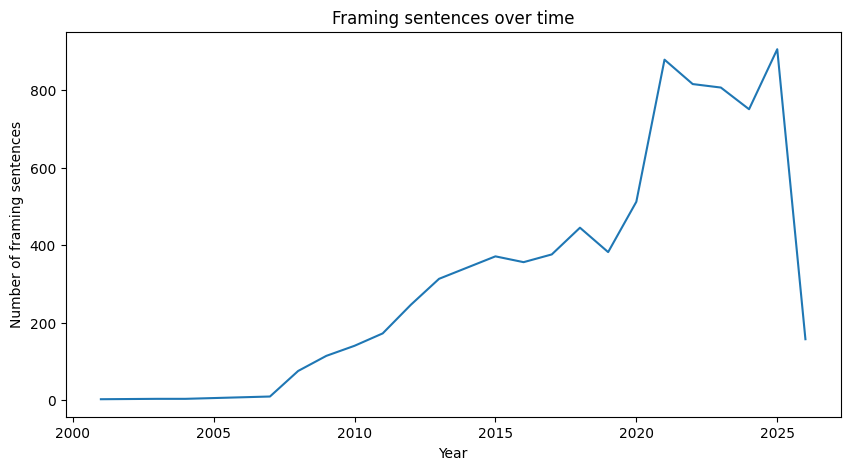

In [2]:
#load data
path = dirs["interim"] / "sentence_extraction" / "thalamus_framing_sentences.csv"
df = pd.read_csv(path)

print(df.shape)
print(df.head())


# 
yearly = df.groupby("year").size().reset_index(name="n_sentences")
yearly.head()
plt.figure(figsize=(10, 5))
plt.plot(yearly["year"], yearly["n_sentences"])
plt.xlabel("Year")
plt.ylabel("Number of framing sentences")
plt.title("Framing sentences over time")
plt.show()


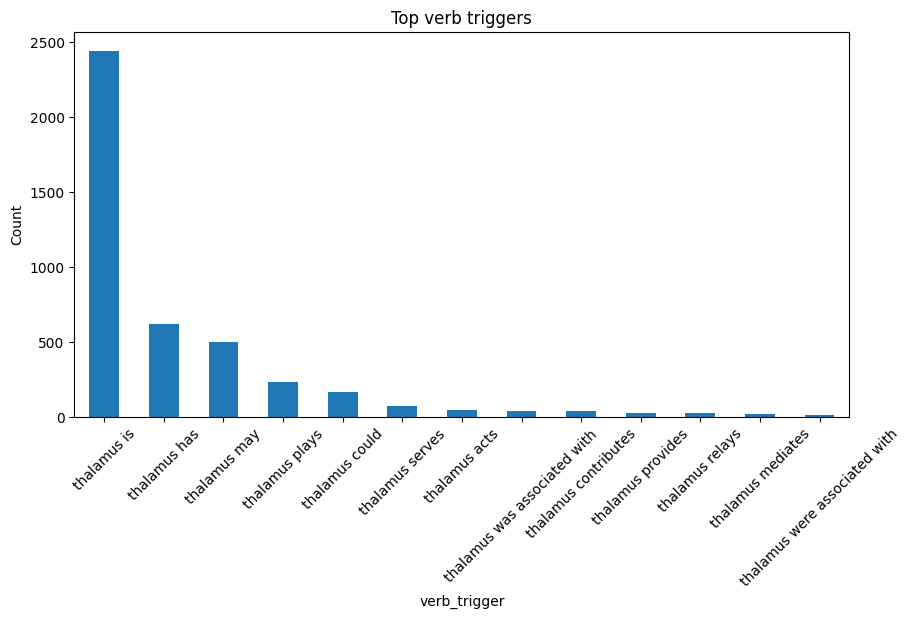

In [3]:
verb_counts = df["verb_trigger"].dropna().value_counts().head(20)
verb_counts
plt.figure(figsize=(10, 5))
verb_counts.plot(kind="bar")
plt.title("Top verb triggers")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

In [4]:
appositive_counts = df["appositive_phrase"].dropna().value_counts().head(20)
appositive_counts
appositive_counts = df["appositive_phrase"].dropna().value_counts().head(20)
appositive_counts

appositive_phrase
basal ganglia                  48
caudate                        41
putamen                        33
hippocampus                    32
amygdala                       25
hypothalamus                   24
caudate nucleus                21
cortex                         20
respectively                   20
cerebellum                     19
striatum                       17
brainstem                      15
lung                           14
VP ventroposterior thalamus    12
i.e.                           12
insula                         10
V3 third ventricle             10
VAVL                            9
midbrain                        8
pallidum                        8
Name: count, dtype: int64

In [5]:
df[df["verb_trigger"] == "the thalamus is"][["year", "title", "sentence"]].head(20)
df[df["appositive_phrase"].notna()][["year", "title", "sentence", "appositive_phrase"]].head(20)

,year,title,sentence,appositive_phrase
3,2007,Parallel driving and modulatory pathways link ...,"Consequently, there is little information on s...",which are thought to underlie the dynamic inte...
4,2007,Parallel driving and modulatory pathways link ...,It has been shown that pallidal hyperactivity ...,including the ventral anterior nucleus
6,2007,Parallel driving and modulatory pathways link ...,Previous studies have shown that the ionotropi...,and the ventral anterior nucleus specifically ...
8,2007,Bilateral Ageusia in a Patient with a Left Ven...,A PET investigation of taste sensation in heal...,insular cortex
10,2006,Sodium channel expression in the ventral poste...,It is known that after peripheral nerve injury...,and that changes in cannabinoid receptors [34]...
13,2006,Parallel thalamic pathways for whisking and to...,We found that a clear dissociation between W a...,in which W and T signals are conveyed mainly b...
14,2006,Parallel thalamic pathways for whisking and to...,An opening was made in the skull overlying the...,and tungsten microelectrodes (0.5–1 MΩ; Alpha ...
18,2004,Differential distribution of the KCl cotranspo...,"Based on the receptor distribution, similar sp...",as also suggested by the abundant extrasynapti...
19,2003,Dopaminergic drug effects on physiological con...,"Drawing on these and other prior sources, we s...",and then from thalamus back to dorsal prefront...
22,2001,Unusual acute encephalitis involving the thala...,These imaging findings can help make a diagnos...,as in our cases


In [55]:
docs = df["sentence"].astype(str).tolist()

timestamps = pd.to_datetime(
    df["year"],
    format="%Y"
)

from bertopic import BERTopic

topic_model = BERTopic(
    min_topic_size=10,
    n_gram_range=(1, 2)
)

topics, probs = topic_model.fit_transform(docs)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 11446.79it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [63]:
import plotly.io as pio
from plotly.subplots import make_subplots

# Always render in browser
pio.renderers.default = "browser"

# --- Compute topics over time ---
topics_over_time = topic_model.topics_over_time(
    docs=docs,
    topics=topics,
    timestamps=timestamps,
    nr_bins=10
)

# --- Generate individual figures ---
fig_time = topic_model.visualize_topics_over_time(
    topics_over_time,
    top_n_topics=10
)

fig_map = topic_model.visualize_topics()

fig_bar = topic_model.visualize_barchart(
    top_n_topics=10
)

# --- Create multi-panel layout ---
fig = make_subplots(
    rows=2,
    cols=2,
    specs=[
        [{"type": "xy"}, {"type": "xy"}],
        [{"type": "xy", "colspan": 2}, None]
    ],
    subplot_titles=[
        "Topic Prevalence Over Time",
        "Topic Similarity Map",
        "Top Words per Topic"
    ]
)

# --- Add traces ---
for trace in fig_time.data:
    fig.add_trace(trace, row=1, col=1)

for trace in fig_map.data:
    fig.add_trace(trace, row=1, col=2)

for trace in fig_bar.data:
    fig.add_trace(trace, row=2, col=1)

# --- Layout tuning ---
fig.update_layout(
    height=900,
    width=1300,
    title="Semantic Framing of Thalamus Research Over Time",
    showlegend=True
)

fig.show()

c:\Users\brouw\anaconda3\envs\thalamus-embed\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
